In [1]:
import sys
sys.path.append("../../../")

In [2]:
from src.utils.dataset import load_dataset
from src.methods.deep_learning.deep_learning import DeepLearningDetector
from src.evaluation.evaluator import Evaluator
from src.experiments.experiment_runner import (
    CleanExperiment,
    RandomSeverityExperiment,
    SeveritySweepExperiment,
    RandomCompositeExperiment
)

/Users/serenelobo/.pyenv/versions/3.11.11/lib/python3.11/site-packages/imagecorruptions/corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [3]:

val_dataset = load_dataset("val")

detector = DeepLearningDetector()

detectors = {
    "deep_learning": detector
}

print(f"Loaded {len(val_dataset)} validation images")

Loaded 291 validation images


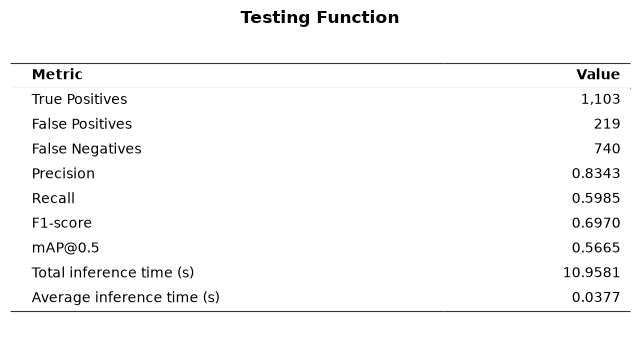

In [4]:
evaluator = Evaluator(detector)

results = evaluator.evaluate(val_dataset, title="Testing Function")

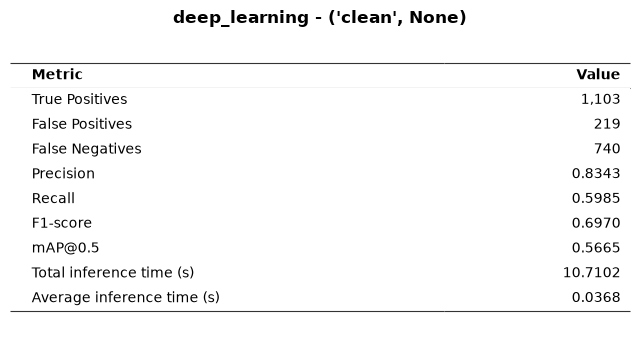

In [5]:
clean_experiment = CleanExperiment()

clean_results = clean_experiment.run(
    dataset=val_dataset,
    detectors=detectors
)

In [6]:
baseline = clean_results[0][("clean", None)]["deep_learning"]

print(f"mAP@0.5: {baseline['map50']:.4f}")
print(f"Precision: {baseline['precision']:.4f}")
print(f"Recall: {baseline['recall']:.4f}")

mAP@0.5: 0.5665
Precision: 0.8343
Recall: 0.5985


In [7]:
random_results = RandomSeverityExperiment(runs=3).run(val_dataset, detectors)

TypeError: gaussian() got an unexpected keyword argument 'multichannel'